# Validation 2 — Kiểm định hoán vị cho hệ số nhân quả đuôi (60 mã)

| Kiểm định | $H_0$ | Cách sinh dữ liệu dưới $H_0$ | Thống kê |
|---|---|---|---|
| (a) Độc lập | các mã độc lập ở đuôi | xáo trộn thời gian **từng cột riêng** | $\hat\Psi_{jk}$, một phía |
| (b) Không có chiều | phân phối đồng thời của $(F_j(X_j), F_k(X_k))$ đối xứng | hoán đổi hai biến trong mỗi phiên với xác suất 1/2 (thang hạng) | $D_{jk} = \hat\Psi_{jk}-\hat\Psi_{kj}$, hai phía |

$p = (1 + \#\{T^{(b)} \text{ cực đoan bằng/hơn}\})/(B+1)$. Hiệu chỉnh nhiều kiểm định: (a) **max-T** của Westfall & Young (1993) — so mỗi $\hat\Psi_{jk}$
với phân phối của $\max$ trên cả 3.540 cặp dưới cùng hoán vị (kiểm soát FWER; Holm cần $p < 0{,}05/3540 \approx 1{,}4\cdot10^{-5}$, không đạt được với $B = 500$);
(b) mỗi cặp có hoán vị riêng nên dùng **Benjamini–Hochberg** (FDR) và Holm, với $B = 4.999$.
Kiểm định trên $z$ và trên phần dư $e$ (đã loại thị trường leave-one-out). Các kiểm định chạy song song (joblib), mỗi cặp có seed riêng.

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "validation"                      # hình png → report/figure/validation, pdf → report/pdf/validation, bảng → report/table/validation
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

import validation as V
from scipy import stats
P = len(SYMBOLS)
OFF = ~np.eye(P, dtype=bool)

Z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid_market.parquet")
z = Z[SYMBOLS]
n, K = len(z), CT.default_k(len(z))
E, beta = V.loo_market_adjust(z)                 # phần dư sau khi loại thị trường leave-one-out
print(f"n = {n} phiên ({Z.index[0]:%d/%m/%Y} → {Z.index[-1]:%d/%m/%Y}), {P} mã, k = {K}")

B_IND, B_SWAP = 500, 4999

n = 2103 phiên (05/06/2018 → 25/11/2026), 60 mã, k = 21


## 1. Kiểm định độc lập

**Các bước:** với $z$ và $e$: 500 bộ dữ liệu xáo trộn → ma trận $\hat\Psi^{(b)}$ (cài đặt vector hoá, ~20 ms/ma trận); p-value một phía
hiệu chỉnh max-T cho 3.540 cặp. Hình: ma trận các cặp bác bỏ $H_0$ (max-T 5%) theo ngành.

z: ngưỡng max-T 5% của Ψ̂ = 0.682


e: ngưỡng max-T 5% của Ψ̂ = 0.682


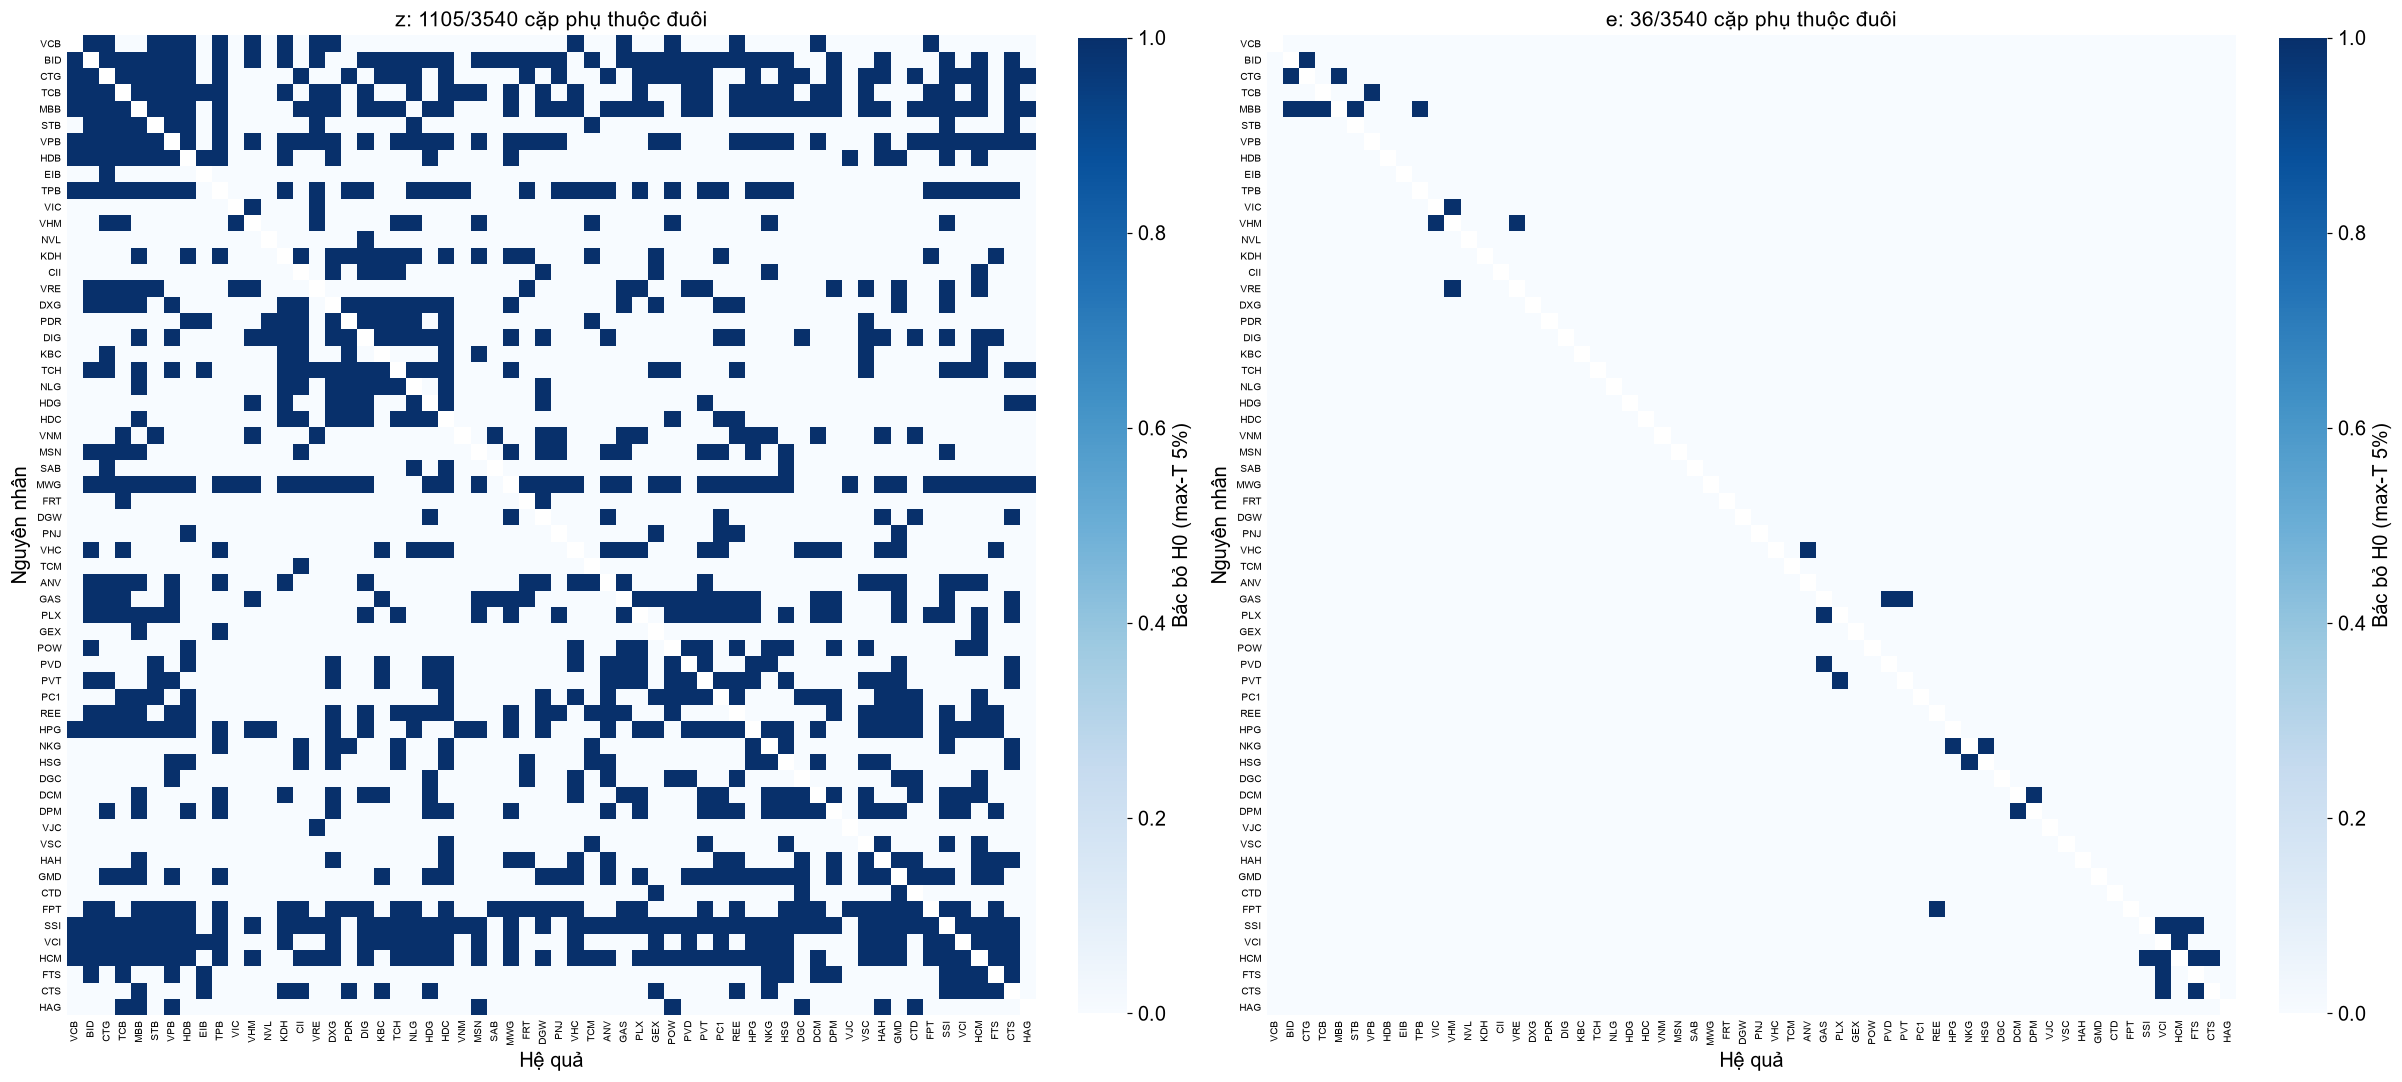

,psi_TB,so_cap_bac_bo_maxT5%
z,0.656,"1,105.000"
e,0.542,36.000


In [2]:
res = {}
for nm, X in {"z": z, "e": E}.items():
    obs = CT.tail_coef_matrix(X, k=K).to_numpy()
    null = V.permutation_null_independence(X, k=K, B=B_IND, seed=3)
    ph = V.maxT_pvalues(obs, null)
    res[nm] = (obs, ph)
    print(f"{nm}: ngưỡng max-T 5% của Ψ̂ = {np.quantile(np.nanmax(null[:, OFF], axis=1), 0.95):.3f}")
ind = pd.DataFrame({nm: {"psi_TB": o[OFF].mean(), "so_cap_bac_bo_maxT5%": int((h[OFF] < 0.05).sum())}
                    for nm, (o, h) in res.items()}).T
U.save_table(ind, "02_independence_summary", FOLDER)
for nm, (o, h) in res.items():
    U.save_table(pd.DataFrame(h, index=SYMBOLS, columns=SYMBOLS), f"02_independence_pholm_{nm}", FOLDER)

fig, axes = plt.subplots(1, 2, figsize=(22, 10))
for ax, (nm, (o, h)) in zip(axes, res.items()):
    sig = pd.DataFrame(np.where(OFF, (h < 0.05).astype(float), np.nan), index=SYMBOLS, columns=SYMBOLS)
    U.make_heatmap(ax, sig, cmap="Blues", vmin=0, vmax=1, fmt=None, tick_fontsize=6.5, cbar_label="Bác bỏ H0 (max-T 5%)",
                   title=f"{nm}: {int(np.nansum(sig.values))}/{int(OFF.sum())} cặp phụ thuộc đuôi")
    ax.set_xlabel("Hệ quả"); ax.set_ylabel("Nguyên nhân")
U.finalize_figure(fig, "02_independence_test", folder=FOLDER); plt.show()
ind

### Phân tích

- Max-T (FWER 5%): **1.105/3.540 cặp** trên $z$ vượt ngưỡng ($\hat\Psi > 0{,}682$); sau khi loại thị trường chỉ còn **36/3.540 cặp** (1%).
- Tỷ lệ cặp có ý nghĩa trên $z$ (31%) thấp hơn với 20 mã (62%) vì ngưỡng max-T tăng theo số cặp (0,682 so với 0,658) và các mã bổ sung ít gắn với thị trường hơn.
- Phụ thuộc đuôi giữa các mã là thật, nhưng **gần như toàn bộ đến từ thị trường**: chỉ ~1% cặp còn phụ thuộc sau khi loại nhân tố chung.

## 2. Kiểm định chiều (hoán đổi đối xứng) cho 235 cặp cùng ngành

**Các bước:** cho 235 cặp **cùng ngành** trên $z$, 235 cặp đó trên $e$, và 60 cặp (VNI, mã) trên $z$: $D$ quan sát và $B = 4.999$ giá trị dưới $H_0$; p hai phía;
q-value Benjamini–Hochberg và Holm trong từng họ.
**Vì sao chỉ cặp cùng ngành:** kiểm định đủ 1.770 cặp × 2 họ × 4.999 hoán vị tốn ~2 giờ; giảm $B$ thì FDR/Holm trên 1.770 cặp mất lực (p nhỏ nhất 1/(B+1)).
Phụ thuộc đuôi sau khi khử thị trường tập trung trong ngành (mục 1, Calibration), nên các cặp cùng ngành là nơi có khả năng tìm thấy chiều nhất.
Hình: phân phối p-value (dưới $H_0$ đúng ở mọi cặp, histogram phẳng) và các cặp có p nhỏ nhất.

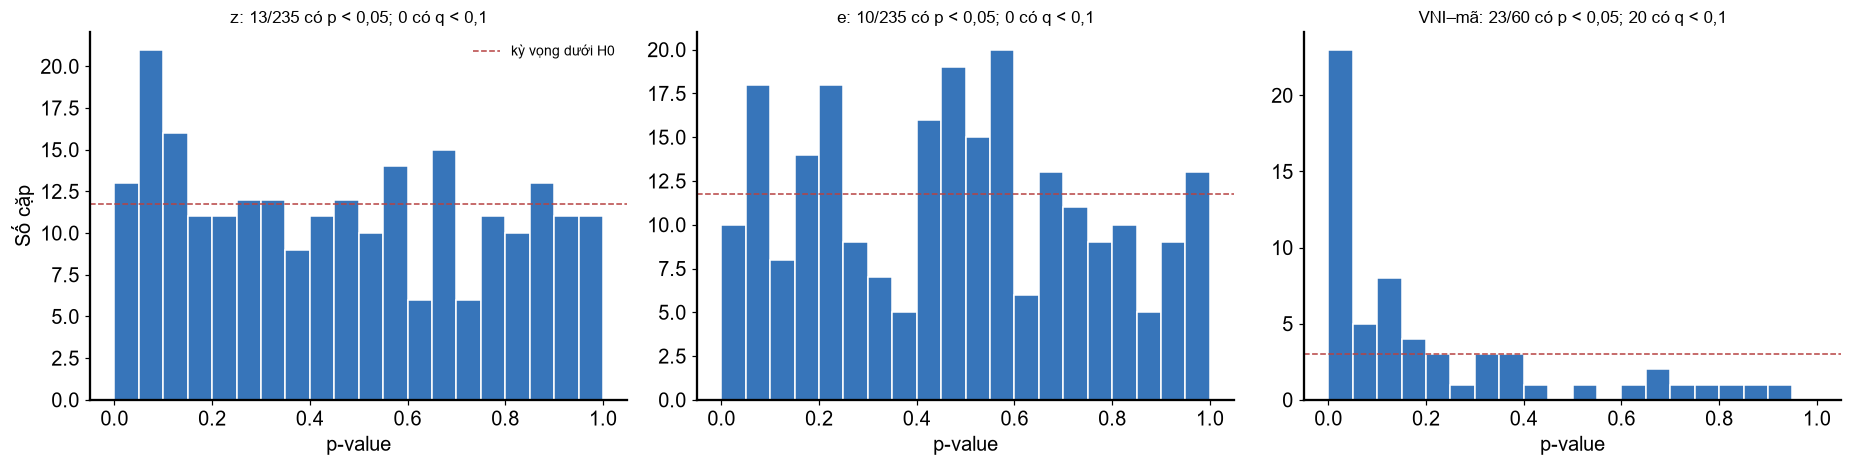

,so_cap,"p<0,05","q_BH<0,1","Holm<0,05"
ho,,,,
VNI–mã,60,23,20,2
e,235,10,0,0
z,235,13,0,0


In [3]:
pairs = [(a, b) for i, a in enumerate(SYMBOLS) for b in SYMBOLS[i + 1:] if U.SECTOR[a] == U.SECTOR[b]]   # 235 cặp cùng ngành
sw = pd.concat([V.swap_test_pairs(z, pairs, k=K, B=B_SWAP, seed=100).assign(ho="z"),
                V.swap_test_pairs(E, pairs, k=K, B=B_SWAP, seed=5000).assign(ho="e"),
                V.swap_test_pairs(Z, [("VNI", s) for s in SYMBOLS], k=K, B=B_SWAP, seed=9000).assign(ho="VNI–mã")],
               ignore_index=True)
U.save_table(sw.set_index(["ho", "cap"]), "02_swap_test", FOLDER)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, fam in zip(axes, ["z", "e", "VNI–mã"]):
    d = sw[sw.ho == fam]
    ax.hist(d.p, bins=np.linspace(0, 1, 21), color=PAL["blue_secondary"], edgecolor="white")
    ax.axhline(len(d) / 20, color=PAL["red_strong"], ls="--", lw=1, label="kỳ vọng dưới H0")
    ax.set_title(f"{fam}: {int((d.p < 0.05).sum())}/{len(d)} có p < 0,05; {int((d.q_bh < 0.1).sum())} có q < 0,1", fontsize=11)
    ax.set_xlabel("p-value")
axes[0].set_ylabel("Số cặp"); axes[0].legend(fontsize=9)
U.finalize_figure(fig, "02_swap_test", folder=FOLDER); plt.show()
sw.groupby("ho").apply(lambda g: pd.Series({"so_cap": len(g), "p<0,05": int((g.p < 0.05).sum()),
                                           "q_BH<0,1": int((g.q_bh < 0.1).sum()), "Holm<0,05": int((g.p_holm < 0.05).sum())}))

In [4]:
sw.sort_values("p").groupby("ho").head(6)[["ho", "cap", "D", "p", "q_bh", "p_holm", "chieu"]].round(4)

,ho,cap,D,p,q_bh,p_holm,chieu
491,VNI–mã,VNI–NLG,0.217,0.000,0.012,0.012,VNI→NLG
509,VNI–mã,VNI–PVT,0.131,0.000,0.012,0.024,VNI→PVT
140,z,VNM–DGW,0.176,0.001,0.141,0.141,VNM→DGW
486,VNI–mã,VNI–DXG,0.155,0.001,0.021,0.070,VNI→DXG
522,VNI–mã,VNI–CTD,0.153,0.001,0.021,0.080,VNI→CTD
462,e,SSI–FTS,0.201,0.002,0.376,0.470,SSI→FTS
493,VNI–mã,VNI–HDC,0.157,0.002,0.026,0.134,VNI→HDC
162,z,MWG–PNJ,0.148,0.002,0.282,0.562,MWG→PNJ
514,VNI–mã,VNI–HSG,0.140,0.003,0.026,0.154,VNI→HSG
325,e,KDH–HDC,-0.173,0.003,0.376,0.749,HDC→KDH


### Phân tích

- **Giữa các mã cùng ngành trên $z$:** 13/235 cặp có p < 0,05 (kỳ vọng do ngẫu nhiên ≈ 12), **0 cặp qua FDR 10%** — không có chiều nhân quả nào giữa hai mã cùng ngành.
- **Trên phần dư $e$:** 10/235 có p < 0,05, 0 cặp qua FDR. Cặp có p nhỏ nhất (SSI → FTS, p = 0,002) không đứng vững sau hiệu chỉnh.
- **VNI – mã:** 57/60 cặp có $D$ cùng dấu (VNI → mã); **20/60 qua FDR 10%** (7 bất động sản — NLG, DXG, PDR, DIG, CII, HDG, HDC; 4 tiêu dùng; 3 năng lượng; HPG, HSG; STB, DCM, CTD, CTS),
  2 qua Holm (VNI → NLG, VNI → PVT). Với 60 mã kiểm định đủ lực để thấy **chiều thị trường → mã** ở mã vừa và nhỏ; notebook 04 cho thấy kiểm định hoán đổi có thể lệch khi hai biến
  có hệ số tải khác nhau, nên đọc kết quả này như xác nhận vai trò "nguồn" của thị trường hơn là quan hệ nhân quả cụ thể.

## 3. Kết luận

1. Phụ thuộc đuôi thật ở 1.105/3.540 cặp, còn 36/3.540 sau khi loại thị trường (max-T, FWER 5%).
2. **Không có chiều nhân quả nào giữa hai mã cùng ngành** sau hiệu chỉnh FDR, cả trên $z$ lẫn trên phần dư.
3. Chiều **VNI → mã** nhất quán về dấu ở 57/60 mã, có ý nghĩa sau FDR ở 20/60 mã (chủ yếu bất động sản và mã vừa/nhỏ).
4. Với hàng nghìn kiểm định, Holm + $B$ nhỏ là vô dụng — phải dùng max-T hoặc FDR.